# Inferensi Sentimen RM 1 



## 0. Pengantar dan parameter

In [1]:
import os
from pathlib import Path

# Akar repo: folder yang memuat src/sentiment_inference.py (notebook dapat dijalankan dari notebooks/).
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sentiment_inference.py").is_file())
os.chdir(REPO)

# ===================== PARAMETER =====================
INPUT_PARQUET = REPO / "outputs/cleaned/reviews_clean_v4.parquet"
TEXT_COL = "text_proposal"
MAX_LENGTH = 128          # sama dengan pelatihan; ganti ke 512 bila diputuskan lain
BATCH_SIZE = 16
DEVICE = "auto"           # auto | mps | cuda | cpu
RUN_MODE = "penuh"        # "uji" -> hanya LIMIT baris; "penuh" -> uji 200 baris dulu, lalu seluruh data
LIMIT = 200 if RUN_MODE == "uji" else None
LIMIT_UJI = 200
REVISION = "5366aae2262a010df28ea88789abc3aeb4df897c"
MIN_ULASAN = 3
AMBANG_TIDAK_YAKIN = 0.6

# Semua keluaran baru ditulis di bawah OUT_ROOT (default: repo). V4_OUT_ROOT hanya untuk uji pengembangan.
OUT_ROOT = Path(os.environ.get("V4_OUT_ROOT", REPO))
SENT_DIR = OUT_ROOT / "outputs/sentiment/v4"
OUTPUT_CSV = SENT_DIR / "sentimen_ulasan_v4.csv"
OUTPUT_UJI_CSV = SENT_DIR / "uji200_v4.csv"
SEKUENS_CSV = OUT_ROOT / "outputs/sentiment/sekuens_produk_v4.csv"
AUDIT_CSV = OUT_ROOT / "outputs/audit_v4/sekuens_audit_v4.csv"
FIG_DIR = OUT_ROOT / "reports/figures/eda_v4"
RINGKASAN_JSON = OUT_ROOT / "reports/v4/ringkasan_angka_v4.json"

# Masukan pendukung (hanya dibaca)
MANIFEST_V4 = REPO / "outputs/cleaned_v4/reports/file_manifest.csv"
RAW_MANIFEST = REPO / "reports/v4/manifest_data_mentah_v4.csv"
PENGECUALIAN = REPO / "references/file_dikecualikan_v4.csv"
TOP_SLANG = REPO / "reports/v4/top_penggantian_slang_v4.csv"
AUDIT_PROPOSAL_JSON = REPO / "reports/v4/log_audit_proposal_v4.json"
V3_CSV = REPO / "outputs/sentiment/sentimen_ulasan_v3.csv"
V3_RINGKASAN = REPO / "outputs/sentiment/sentimen_ulasan_v3_ringkasan.json"

# Jangan menimpa: berhenti di awal bila keluaran sudah ada.
_targets = [OUTPUT_UJI_CSV, SEKUENS_CSV, AUDIT_CSV, RINGKASAN_JSON] + ([OUTPUT_CSV] if RUN_MODE == "penuh" else [])
_ada = [str(p) for p in _targets if p.exists()]
assert not _ada, f"BERHENTI: keluaran sudah ada dan tidak akan ditimpa: {_ada}. Pakai OUT_ROOT/nama lain."
assert RUN_MODE in ("uji", "penuh"), "RUN_MODE harus 'uji' atau 'penuh'"
print("REPO      :", REPO)
print("OUT_ROOT  :", OUT_ROOT)
print("RUN_MODE  :", RUN_MODE, "| MAX_LENGTH:", MAX_LENGTH, "| BATCH_SIZE:", BATCH_SIZE, "| DEVICE:", DEVICE)

REPO      : /Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA
OUT_ROOT  : /Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA
RUN_MODE  : penuh | MAX_LENGTH: 128 | BATCH_SIZE: 16 | DEVICE: auto


In [2]:
import hashlib, json, platform, subprocess, sys, time, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

import torch, transformers
from src import sentiment_inference as si
from src import run_sentiment_inference as rsi
from src import export_sekuens as es
from src.eda import ringkasan as eda
from src.eda.ringkasan import WARNA, LABEL_NAMES, PROB_COLUMNS, URUTAN_NASKAH, pilih_prob, as_bool

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True})
grafik = eda.PenyimpanGrafik(FIG_DIR)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(1 << 20), b""):
            h.update(blok)
    return h.hexdigest()

def git(*args):
    return subprocess.run(["git", *args], capture_output=True, text=True, cwd=REPO).stdout.strip()

mps_ok = getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available()
device_terpilih = si.pick_device(DEVICE, torch.cuda.is_available(), bool(mps_ok))
provenance = {
    "tanggal": datetime.now().astimezone().isoformat(timespec="seconds"),
    "git_head": git("rev-parse", "--short", "HEAD"),
    "git_berkas_berubah": len([l for l in git("status", "--short").splitlines() if l.strip()]),
    "input": str(INPUT_PARQUET.relative_to(REPO)),
    "sha256_input": sha256(INPUT_PARQUET),
    "python": platform.python_version(), "torch": torch.__version__,
    "transformers": transformers.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "device": device_terpilih, "mps_tersedia": bool(mps_ok), "cuda_tersedia": torch.cuda.is_available(),
    "repo_model": si.REPO_ID, "revision_model": REVISION,
    "max_length": MAX_LENGTH, "max_length_pelatihan": si.MAX_LENGTH_PELATIHAN, "batch_size": BATCH_SIZE,
    "HF_TOKEN_tersedia": bool(os.environ.get(si.TOKEN_ENV)),   # hanya ya/tidak; nilainya tidak dicetak
}
display(pd.Series(provenance, name="nilai").to_frame())

,nilai
tanggal,2026-10-15T11:06:28+07:00
git_head,80dea6e
git_berkas_berubah,9
input,outputs/cleaned/reviews_clean_v4.parquet
sha256_input,a5959b4414cdbf2095922dfaef8b157a23744e3763b48236738ed0aa6252a92b
python,3.11.7
torch,2.12.1
transformers,5.12.1
pandas,2.3.3
matplotlib,3.10.8


## 1. Memuat data

In [3]:
df = pd.read_parquet(INPUT_PARQUET)
print(f"Baris: {len(df):,} | Kolom: {df.shape[1]}")
print("Kolom:", ", ".join(df.columns))
contoh = df[["nama_toko", "nama_produk", "review", "timestamp", TEXT_COL]].head(5)
display(contoh.rename(columns={"nama_toko": "Nama Toko", "nama_produk": "Nama Produk",
                               "review": "Review", "timestamp": "Timestamp"}))

Baris: 73,248 | Kolom: 29
Kolom: review_id, product_id, nama_toko, nama_produk, review, text_light, aspect_tags, timestamp, timestamp_has_time, timestamp_raw, timestamp_status, row_order, source_file, fragment_cols, n_fragments, n_chars, n_words, is_empty, is_short, is_technical_duplicate, is_text_duplicate, dup_group_size, seller_reply_suspect, include_for_inference, seq_in_product, file_dup_group, schema_family, text_proposal, text_proposal_kosong


,Nama Toko,Nama Produk,Review,Timestamp,text_proposal
0,1688.shopp,Oppo A31,aman semoga awet,2026-04-02 01:42:00,aman semoga awet
1,1688.shopp,Oppo A31,"Maaf hp lama sy TDK bs bwt vidio mangka sy bli Bru Alhamdulillah walau awal,a ragu"" tr...",2026-04-02 08:02:00,"Maaf hp lama sy TIDAK bs buat vidio mangka sy beli Baru Alhamdulillah walau awal,a rag..."
2,1688.shopp,Oppo A31,"Beli empat dan sudah sampai semua, ok punya lah ini toko...👌👌",2026-04-03 20:05:00,"Beli empat dan sudah sampai semua, ok punya lah ini toko."
3,1688.shopp,Oppo A31,Bagus 2 kli sdh beli disini,2026-04-04 12:20:00,Bagus 2 kali sudah beli disini
4,1688.shopp,Oppo A31,Pembelian yg ke 2. \nBarang bagus dan sesuai.,2026-04-05 10:10:00,Pembelian yg ke 2. Barang bagus dan sesuai.


## 2. EDA sebelum inferensi

### 2a. Corong data
Satuan tahap pertama adalah berkas, sedangkan tahap berikutnya adalah baris ulasan, jadi keduanya
ditampilkan di dua panel terpisah.

,tahap,satuan,jumlah
0,CSV data di folder mentah,berkas,456
1,Berkas dipetakan (status ok),berkas,441
2,Berkas diproses (ada kolom ulasan),berkas,438
3,Baris sumber (rekaman CSV),baris,111849
4,Baris bersih (ulasan),baris,73248
5,include_for_inference,baris,72881
6,include & text_proposal tidak kosong,baris,72830
7,... pada produk >= 3 ulasan,baris,72830


Berkas dikecualikan (aturan salinan v4): 14
Status manifest: {'diproses': 438, 'dikecualikan': 16, 'dilewati': 3}


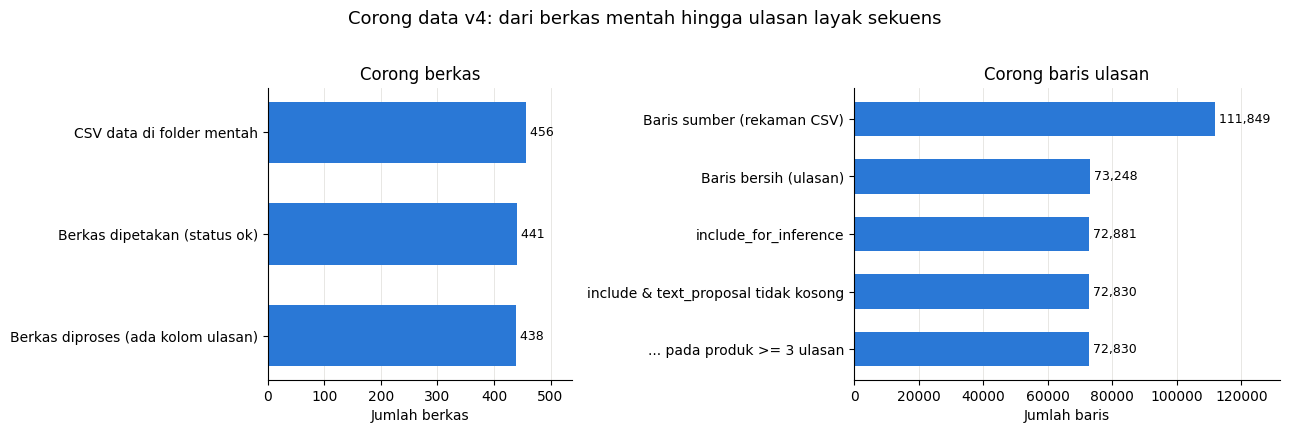

In [4]:
manifest = pd.read_csv(MANIFEST_V4, encoding="utf-8-sig")
raw_manifest = pd.read_csv(RAW_MANIFEST, encoding="utf-8-sig")
n_berkas_csv = int((raw_manifest["file"] != "pemetaan_file_toko_produk.csv").sum())
corong = eda.corong_data(manifest, df, n_berkas_csv=n_berkas_csv, min_ulasan=MIN_ULASAN)
display(corong)
pengecualian = pd.read_csv(PENGECUALIAN, encoding="utf-8-sig")
print("Berkas dikecualikan (aturan salinan v4):", int((pengecualian["keputusan"] == "kecualikan").sum()))
print("Status manifest:", manifest["status"].str.split(":").str[0].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
for ax, satuan in zip(axes, ["berkas", "baris"]):
    sub = corong[corong["satuan"] == satuan].iloc[::-1]
    ax.barh(sub["tahap"], sub["jumlah"], color="#2a78d6", height=0.6)
    for y, v in enumerate(sub["jumlah"]):
        ax.text(v, y, f" {v:,}", va="center", fontsize=9)
    ax.set_xlabel(f"Jumlah {satuan}")
    ax.set_xlim(0, sub["jumlah"].max() * 1.18)
    ax.grid(axis="y", visible=False)
axes[0].set_title("Corong berkas")
axes[1].set_title("Corong baris ulasan")
fig.suptitle("Corong data v4: dari berkas mentah hingga ulasan layak sekuens", y=1.02, fontsize=13)
fig.tight_layout(); grafik.simpan(fig, "corong_data"); plt.show()

**Interpretasi.** Dari 456 CSV data, 441 berkas dipetakan (14 salinan dan 1 berkas hanya-nama-toko dikecualikan) dan 438 berkas menghasilkan ulasan. 111.849 rekaman CSV menyusut menjadi 73.248 ulasan karena banyak rekaman tidak berisi teks ulasan, sedangkan penyaringan include dan teks kosong hanya membuang sekitar 0,6% baris lagi.

### 2b. Ringkasan per toko dan per produk

Toko: 151 | Produk: 432 | Ulasan: 73,248


,ulasan per produk
count,432.0
mean,169.6
std,335.1
min,3.0
25%,26.8
50%,65.0
75%,167.5
90%,362.9
95%,520.9
max,3628.0


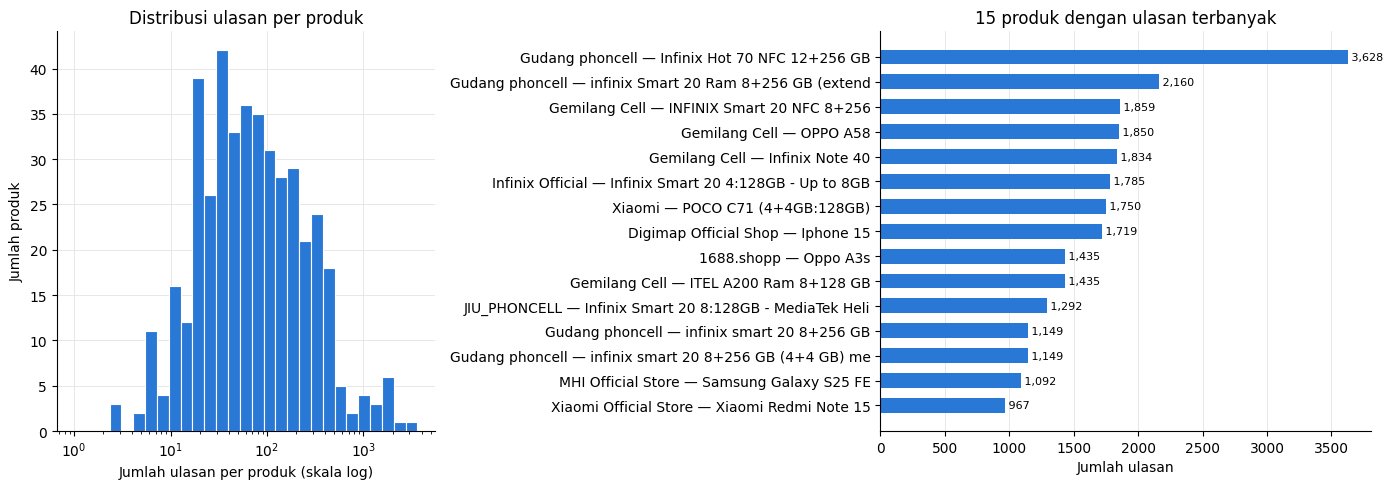

In [5]:
produk = eda.ringkasan_produk(df)
print(f"Toko: {df['nama_toko'].nunique()} | Produk: {df['product_id'].nunique()} | Ulasan: {len(df):,}")
display(produk["n_ulasan"].describe(percentiles=[.25, .5, .75, .9, .95]).round(1).to_frame("ulasan per produk"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})
bins = np.logspace(0, np.log10(produk["n_ulasan"].max() + 1), 30)
axes[0].hist(produk["n_ulasan"], bins=bins, color="#2a78d6", edgecolor="white", linewidth=0.8)
axes[0].set_xscale("log")
axes[0].set_xlabel("Jumlah ulasan per produk (skala log)")
axes[0].set_ylabel("Jumlah produk")
axes[0].set_title("Distribusi ulasan per produk")
top15 = produk.head(15).iloc[::-1]
label = (top15["nama_toko"] + " — " + top15["nama_produk"]).str.slice(0, 55)
axes[1].barh(label, top15["n_ulasan"], color="#2a78d6", height=0.6)
for y, v in enumerate(top15["n_ulasan"]):
    axes[1].text(v, y, f" {v:,}", va="center", fontsize=8)
axes[1].set_xlabel("Jumlah ulasan")
axes[1].set_title("15 produk dengan ulasan terbanyak")
axes[1].grid(axis="y", visible=False)
fig.tight_layout(); grafik.simpan(fig, "ulasan_per_produk"); plt.show()

**Interpretasi.** Jumlah ulasan per produk sangat menceng ke kanan (median 65, maksimum 3.628), sehingga beberapa produk besar mendominasi data; produk teratas (Gudang phoncell Infinix Hot 70) adalah gabungan berkas lama dan berkas baru dengan product_key sama yang ulasannya sebagian besar tumpang tindih.

### 2c. Kualitas teks

In [6]:
kualitas = eda.kualitas_teks(df, TEXT_COL, short_words=2)
display(kualitas)

,indikator,n,persen
0,text_proposal kosong,64,0.09
1,sangat pendek (1..2 kata),8503,11.61
2,is_short (text_light < min_review_length),20,0.03
3,duplikat teknis (is_technical_duplicate),347,0.47
4,duplikat teks (is_text_duplicate),9897,13.51
5,balasan penjual dicurigai (seller_reply_suspect),30,0.04


**Interpretasi.** Teks kosong (0,09%), balasan penjual dicurigai (0,04%), dan duplikat teknis (0,47%) sangat sedikit, tetapi 11,6% ulasan sangat pendek (<= 2 kata) dan 13,5% bertanda duplikat teks sehingga kebijakan duplikat teks berpengaruh nyata pada sekuens.

### 2d. Panjang teks
Jumlah token dihitung dengan tokenizer model yang sama (termasuk `[CLS]` dan `[SEP]`), tanpa pemotongan,
memakai fungsi `_token_lengths` dari `src.sentiment_inference`. Tokenizer dimuat dari cache lokal pada
revision yang dipin.

,karakter,kata,token
count,73184.0,73184.0,73184.0
mean,87.2,13.6,19.0
std,81.5,12.9,16.3
min,1.0,1.0,3.0
50%,68.0,10.0,15.0
90%,180.0,28.0,38.0
95%,232.0,36.0,48.0
99%,375.2,60.0,78.0
max,2166.0,370.0,447.0


,max_length,n_terpotong,persen_terpotong
0,128,123,0.168
1,512,0,0.000


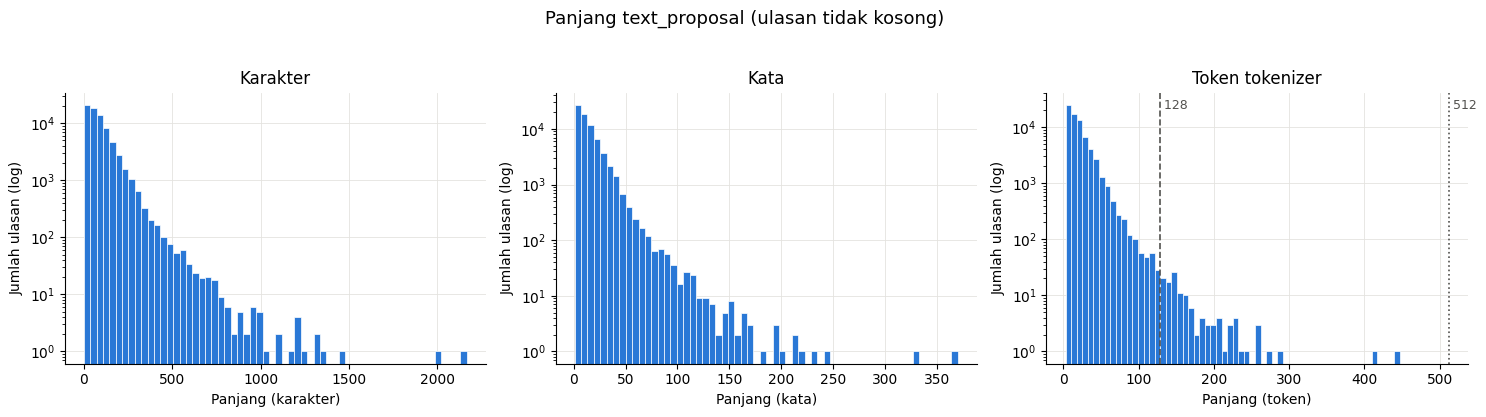

In [7]:
from transformers import AutoTokenizer
model_path, _rev = si.resolve_model_path(si.SentimentModelConfig(revision=REVISION))
tokenizer = AutoTokenizer.from_pretrained(model_path, local_files_only=True)

nonempty = ~as_bool(df["text_proposal_kosong"])
teks = df.loc[nonempty, TEXT_COL].astype(str)
panjang = pd.DataFrame({"karakter": teks.str.len(), "kata": eda.jumlah_kata(teks),
                        "token": si._token_lengths(tokenizer, teks.str.strip().tolist())}, index=teks.index)
display(panjang.describe(percentiles=[.5, .9, .95, .99]).round(1))
terpotong = eda.tabel_terpotong(panjang["token"], sorted({MAX_LENGTH, 128, 512}))
display(terpotong)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kol, judul in zip(axes, ["karakter", "kata", "token"], ["Karakter", "Kata", "Token tokenizer"]):
    ax.hist(panjang[kol], bins=60, color="#2a78d6", edgecolor="white", linewidth=0.5)
    ax.set_yscale("log"); ax.set_xlabel(f"Panjang ({kol})"); ax.set_ylabel("Jumlah ulasan (log)")
    ax.set_title(judul)
for m, gaya in [(128, "--"), (512, ":")]:
    axes[2].axvline(m, color="#52514e", linestyle=gaya, linewidth=1.2)
    axes[2].text(m, axes[2].get_ylim()[1] * 0.5, f" {m}", color="#52514e", fontsize=9)
fig.suptitle("Panjang text_proposal (ulasan tidak kosong)", y=1.03, fontsize=13)
fig.tight_layout(); grafik.simpan(fig, "panjang_teks"); plt.show()

**Interpretasi.** Median ulasan hanya 15 token dan 99% di bawah 78 token, sehingga pada MAX_LENGTH 128 hanya 0,17% ulasan (123) yang terpotong dan pada 512 tidak ada yang terpotong.

### 2e. Waktu

,kategori,n,persen
0,timestamp valid,71735,97.93
1,timestamp dengan jam,34847,47.57
2,timestamp tanpa jam (tanggal saja),36888,50.36
3,timestamp tidak valid (NaT),1513,2.07


,timestamp_status,n
0,ok,71735
1,relatif,1513


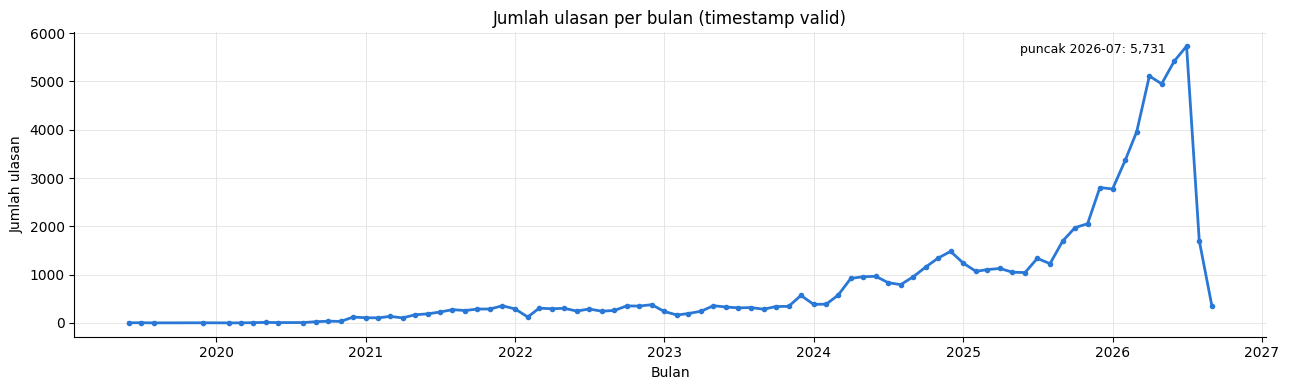

Rentang: 2019-06 s.d. 2026-09


In [8]:
waktu, status_ts = eda.ringkasan_waktu(df)
display(waktu); display(status_ts)
bulanan = eda.ulasan_per_bulan(df)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(bulanan.index.to_timestamp(), bulanan.values, color="#2a78d6", linewidth=2, marker="o", markersize=3)
ax.set_xlabel("Bulan"); ax.set_ylabel("Jumlah ulasan")
ax.set_title("Jumlah ulasan per bulan (timestamp valid)")
puncak = bulanan.idxmax()
ax.annotate(f"puncak {puncak}: {bulanan.max():,}", (puncak.to_timestamp(), bulanan.max()),
            textcoords="offset points", xytext=(-120, -5), fontsize=9)
fig.tight_layout(); grafik.simpan(fig, "ulasan_per_bulan"); plt.show()
print("Rentang:", bulanan.index.min(), "s.d.", bulanan.index.max())

**Interpretasi.** Ulasan menumpuk pada 2025-2026 dengan puncak Juli 2026, sedangkan penurunan tajam Agustus-September 2026 kemungkinan besar mencerminkan batas waktu scraping, bukan penurunan minat; 50,4% timestamp hanya memuat tanggal tanpa jam.

### 2f. Efek preprocessing
Angka jejak penggantian slang diambil dari audit `src.cleaning.audit_proposal` v4 (regenerasi identik dengan parquet).

,nilai
baris total,73248
baris berubah (review != text_proposal),49432
text_proposal kosong,64
jumlah penggantian slang,67888
pasangan slang terpakai,1179


,baris berubah
nfkc,798
normalisasi_pemisah_unicode,62
hapus_url,7
hapus_emoji_karakter_khusus,29070
ringkas_tanda_baca,12012
hapus_angka_panjang,13
normalisasi_typo_huruf_berulang,4588
normalisasi_slang,29652
rapikan_spasi,30369


,review,text_proposal
0,"baik,,,","baik,"
1,masyaallah.. bagus... terimakasih karna sudah amanah.. mau pesen lagi,masyaallah. bagus. terimakasih karena sudah amanah. mau pesan lagi
2,ponsel berfungsi dengan baik | lumayan dengan harga segituu,ponsel berfungsi dengan baik lumayan dengan harga segituu
3,Pengiriman cepat 👍 pengemasan cepat 👍 alhamdulillah uda 2 hari di pake gda kendala :) ...,Pengiriman cepat pengemasan cepat alhamdulillah sudah 2 hari di pakai enggak ada kenda...
4,Recommended seller Sesuai dengan iklanya | bagus | sesuai,Recommended seller Sesuai dengan iklanya bagus sesuai
5,sesuai pesanan 🫰,sesuai pesanan
6,bagus | baru coba | Tp pengiriman agak lambat respon penjual juga lama,bagus baru coba Tp pengiriman agak lambat respon penjual juga lama
7,"di terima dengan baik dan aman | Banyak pilihan dengan merk dan type di brand lain, da...","di terima dengan baik dan aman Banyak pilihan dengan merk dan type di brand lain, dan ..."


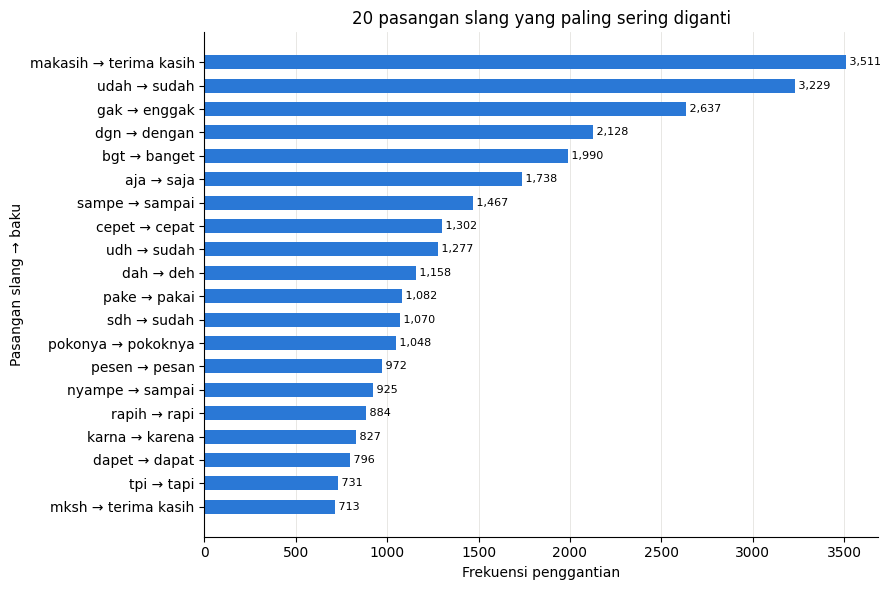

In [9]:
audit_prop = json.loads(AUDIT_PROPOSAL_JSON.read_text(encoding="utf-8"))["verifikasi"]
efek = pd.Series({
    "baris total": audit_prop["n_baris"],
    "baris berubah (review != text_proposal)": audit_prop["n_berubah"],
    "text_proposal kosong": audit_prop["n_kosong"],
    "jumlah penggantian slang": audit_prop["jumlah_slang_dinormalkan"],
    "pasangan slang terpakai": audit_prop["jumlah_pasangan_slang_terpakai"],
}, name="nilai")
display(efek.to_frame())
display(pd.Series(audit_prop["baris_berubah_per_aturan"], name="baris berubah").to_frame())
berubah = df[df["review"] != df[TEXT_COL]]
display(berubah.sample(n=8, random_state=42)[["review", TEXT_COL]].reset_index(drop=True))

top_slang = pd.read_csv(TOP_SLANG).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_slang["slang"] + " → " + top_slang["baku"], top_slang["frekuensi_penggantian"],
        color="#2a78d6", height=0.6)
for y, v in enumerate(top_slang["frekuensi_penggantian"]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8)
ax.set_xlabel("Frekuensi penggantian"); ax.set_ylabel("Pasangan slang → baku")
ax.set_title("20 pasangan slang yang paling sering diganti")
ax.grid(axis="y", visible=False)
fig.tight_layout(); grafik.simpan(fig, "top_slang"); plt.show()

**Interpretasi.** Normalisasi slang mengganti 67.888 kemunculan dari 1.179 pasangan kamus; penggantian didominasi beberapa singkatan umum seperti pada grafik, sehingga kualitas beberapa pasangan teratas paling menentukan isi text_proposal.

### 2g. Kata dan bigram paling sering pada text_proposal
Unigram tanpa kata tugas (`src.eda.ringkasan.KATA_TUGAS`); bigram dibuang hanya bila kedua katanya kata tugas.

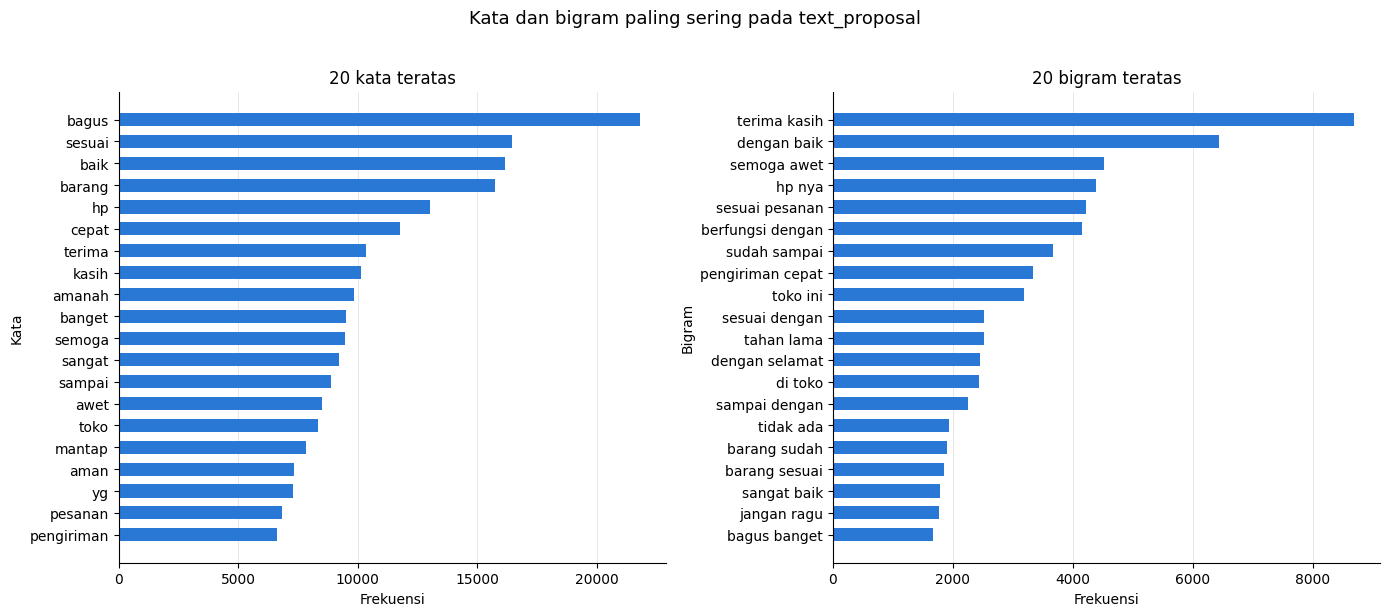

In [10]:
uni = eda.top_ngram(teks, n=1, k=20).iloc[::-1]
bi = eda.top_ngram(teks, n=2, k=20).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, tab, judul in [(axes[0], uni, "20 kata teratas"), (axes[1], bi, "20 bigram teratas")]:
    ax.barh(tab["ngram"], tab["frekuensi"], color="#2a78d6", height=0.6)
    ax.set_xlabel("Frekuensi"); ax.set_title(judul); ax.grid(axis="y", visible=False)
axes[0].set_ylabel("Kata"); axes[1].set_ylabel("Bigram")
fig.suptitle("Kata dan bigram paling sering pada text_proposal", y=1.02, fontsize=13)
fig.tight_layout(); grafik.simpan(fig, "kata_bigram"); plt.show()

**Interpretasi.** Kata dan bigram tersering menggambarkan ulasan yang didominasi pujian umum tentang barang, pengiriman, dan kesesuaian pesanan, konsisten dengan dominasi kelas positif setelah inferensi.

## 3. Verifikasi pemetaan label
Model dimuat sekali (cache lokal; token dari `HF_TOKEN` hanya bila perlu mengunduh). `id2label` wajib
`{0: negatif, 1: netral, 2: positif}` dan tiga kalimat uji Bab 3.4.2 wajib menghasilkan argmax sesuai harapan.

In [11]:
bundle = si.load_sentiment_model(si.SentimentModelConfig(
    revision=REVISION, device=DEVICE, batch_size=BATCH_SIZE, max_length=MAX_LENGTH))
print("device :", bundle.device)
print("id2label:", bundle.meta["id2label"])
try:
    indeks = si.check_label_mapping(bundle.meta["id2label"])
except si.ModelCheckError as exc:
    raise RuntimeError(f"BERHENTI: pemetaan label tidak sesuai: {exc}") from exc
print("indeks logit per sentimen:", indeks)

uji_label = si.check_label_semantics(bundle)
tabel_label = pd.DataFrame([{"kalimat": c["kalimat"], "harapan": c["harapan"], "argmax": c["argmax"],
                             **{k: round(v, 4) for k, v in c["probabilitas"].items()}, "lulus": c["lulus"]}
                            for c in uji_label])
display(tabel_label)
if not tabel_label["lulus"].all():
    raise RuntimeError("BERHENTI: kalimat uji label tidak sesuai harapan; jangan lanjut inferensi.")
print("Pemetaan label sesuai.")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

device : mps
id2label: {0: 'negatif', 1: 'netral', 2: 'positif'}
indeks logit per sentimen: {'negative': 0, 'neutral': 1, 'positive': 2}


,kalimat,harapan,argmax,p_negatif,p_netral,p_positif,lulus
0,"Barangnya bagus banget, sesuai deskripsi, pengiriman cepat",positif,positif,0.0011,0.0008,0.9982,True
1,"Barang sudah sampai, belum saya coba",netral,netral,0.0765,0.9016,0.0219,True
2,"Barang rusak, tidak sesuai foto, kecewa berat",negatif,negatif,0.9971,0.0006,0.0023,True


Pemetaan label sesuai.


## 4. Inferensi
Inferensi dijalankan lewat `src.run_sentiment_inference.run(...)` (CLI yang sama dengan v3) memakai bundle
model di atas, dengan `--save-logits --save-diagnostics`. Progress bar dipasang dengan membungkus fungsi
`forward` bundle tanpa mengubah modul; hitungannya mencakup teks pemeriksaan model (3 kalimat uji
+ 2 × 16 sampel). Pertama mode uji 200 baris, lalu mode penuh.

In [12]:
from tqdm import tqdm

def jalankan_inferensi(output_csv, limit=None):
    argv = ["--input", str(INPUT_PARQUET), "--text-col", TEXT_COL, "--output", str(output_csv),
            "--revision", REVISION, "--device", DEVICE, "--batch-size", str(BATCH_SIZE),
            "--max-length", str(MAX_LENGTH), "--save-logits", "--save-diagnostics"]
    if limit:
        argv += ["--limit", str(limit)]
    args = rsi.build_parser().parse_args(argv)
    sub = df.head(limit) if limit else df
    n_teks = int((~as_bool(sub["text_proposal_kosong"])).sum())
    total = n_teks + 3 + 2 * min(args.sample_checks, n_teks)
    asli = bundle.forward
    bar = tqdm(total=total, unit="teks", desc=output_csv.name, mininterval=10, file=sys.stdout)
    def forward(batch):
        hasil = asli(batch)
        bar.update(len(batch["input_ids"]))
        return hasil
    bundle.forward = forward
    mulai = time.time()
    try:
        kode = rsi.run(args, bundle=bundle)
    finally:
        bundle.forward = asli
        bar.close()
    durasi = time.time() - mulai
    assert kode == rsi.EXIT_OK, f"Inferensi berhenti dengan kode {kode}"
    ringkas = json.loads(output_csv.with_name(output_csv.stem + "_ringkasan.json").read_text(encoding="utf-8"))
    print(f"Durasi: {durasi:.1f} detik")
    return ringkas, durasi

ringkas_uji, durasi_uji = jalankan_inferensi(OUTPUT_UJI_CSV, limit=LIMIT_UJI)
hasil_uji = pd.read_csv(OUTPUT_UJI_CSV, encoding="utf-8-sig", low_memory=False)
display(hasil_uji[[TEXT_COL, *PROB_COLUMNS, "label_argmax", "n_token"]].head(10))
display(pd.DataFrame(ringkas_uji["ringkasan"]["distribusi_argmax"]).T)


uji200_v4.csv:   0%|          | 0/235 [00:00<?, ?teks/s]

Input: "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/cleaned/reviews_clean_v4.parquet" (200 baris)
Model siap di device: mps


  [OK] id2label = {0:negatif, 1:netral, 2:positif} -- {0: 'negatif', 1: 'netral', 2: 'positif'}
  [OK] tokenizer.model_max_length (informasi) -- nilai: 128; max_length inferensi eksplisit: 128
  [OK] max_length <= max_position_embeddings -- 128 <= 512
  [OK] semantik label positif -- 'Barangnya bagus banget, sesuai deskripsi, pengiriman cepat'; p_negatif=0.0011; p_netral=0.0008; p_positif=0.9982; argmax=positif; harapan=positif
  [OK] semantik label netral -- 'Barang sudah sampai, belum saya coba'; p_negatif=0.0765; p_netral=0.9016; p_positif=0.0219; argmax=netral; harapan=netral
  [OK] semantik label negatif -- 'Barang rusak, tidak sesuai foto, kecewa berat'; p_negatif=0.9971; p_netral=0.0006; p_positif=0.0023; argmax=negatif; harapan=negatif
  [OK] tidak ada NaN/Inf pada probabilitas -- 16 teks diuji
  [OK] probabilitas berjumlah 1 (<=1e-6) -- deviasi maks 1.11e-16
  [OK] hasil batch = hasil satu-satu (<= 0.0001) -- selisih maks 3.68e-07



RINGKASAN SANITY CHECK
Baris total / diinferensi / kosong : 200 / 200 / 0
Sangat pendek (<= 2 kata)       : 43
Terpotong (> 128 token)          : 0 (0.0%)
Rata-rata p_netral                 : 0.054483232467954765
  argmax negatif : 26 (13.0%)
  argmax netral  : 9 (4.5%)
  argmax positif : 165 (82.5%)
Keluaran: "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/sentiment/v4/uji200_v4.csv"

uji200_v4.csv: 100%|██████████| 235/235 [00:01<00:00, 174.66teks/s]


Durasi: 1.3 detik


,text_proposal,p_negatif,p_netral,p_positif,label_argmax,n_token
0,aman semoga awet,0.001861,0.004025,0.994114,positif,5
1,"Maaf hp lama sy TIDAK bs buat vidio mangka sy beli Baru Alhamdulillah walau awal,a rag...",0.011925,0.018829,0.969245,positif,40
2,"Beli empat dan sudah sampai semua, ok punya lah ini toko.",0.077505,0.842433,0.080062,netral,15
3,Bagus 2 kali sudah beli disini,0.003285,0.004491,0.992224,positif,8
4,Pembelian yg ke 2. Barang bagus dan sesuai.,0.000962,0.001009,0.998029,positif,12
5,baik,0.001253,0.001256,0.997490,positif,3
6,"Jangan ragu buat beli, semoga amanah dan barokah paket sesuai deskripsi baru tersegel,...",0.007942,0.043087,0.948972,positif,23
7,Di vivo yg datang oppo. Di iklan vivo di kirim oppo,0.001625,0.997705,0.000670,netral,14
8,Bagus,0.000817,0.000731,0.998451,positif,3
9,bagus banget kak hp nya,0.000877,0.001250,0.997872,positif,7


,n,persen
negatif,26.0,13.0
netral,9.0,4.5
positif,165.0,82.5


In [13]:
if RUN_MODE == "penuh":
    ringkas_penuh, durasi_penuh = jalankan_inferensi(OUTPUT_CSV)
    HASIL_CSV = OUTPUT_CSV
else:
    ringkas_penuh, durasi_penuh = ringkas_uji, durasi_uji
    HASIL_CSV = OUTPUT_UJI_CSV
hasil = pd.read_csv(HASIL_CSV, encoding="utf-8-sig", low_memory=False)
print(f'Keluaran: "{HASIL_CSV.relative_to(OUT_ROOT)}" ({len(hasil):,} baris)')
display(pd.Series({k: ringkas_penuh["meta"][k] for k in
                   ["device", "max_length", "max_length_pelatihan", "revision", "durasi_detik", "status"]},
                  name="nilai").to_frame())


sentimen_ulasan_v4.csv:   0%|          | 0/73219 [00:00<?, ?teks/s]

Input: "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/cleaned/reviews_clean_v4.parquet" (73,248 baris)
Model siap di device: mps


  [OK] id2label = {0:negatif, 1:netral, 2:positif} -- {0: 'negatif', 1: 'netral', 2: 'positif'}
  [OK] tokenizer.model_max_length (informasi) -- nilai: 128; max_length inferensi eksplisit: 128
  [OK] max_length <= max_position_embeddings -- 128 <= 512
  [OK] semantik label positif -- 'Barangnya bagus banget, sesuai deskripsi, pengiriman cepat'; p_negatif=0.0011; p_netral=0.0008; p_positif=0.9982; argmax=positif; harapan=positif
  [OK] semantik label netral -- 'Barang sudah sampai, belum saya coba'; p_negatif=0.0765; p_netral=0.9016; p_positif=0.0219; argmax=netral; harapan=netral
  [OK] semantik label negatif -- 'Barang rusak, tidak sesuai foto, kecewa berat'; p_negatif=0.9971; p_netral=0.0006; p_positif=0.0023; argmax=negatif; harapan=negatif
  [OK] tidak ada NaN/Inf pada probabilitas -- 16 teks diuji
  [OK] probabilitas berjumlah 1 (<=1e-6) -- deviasi maks 1.11e-16
  [OK] hasil batch = hasil satu-satu (<= 0.0001) -- selisih maks 4.80e-07



sentimen_ulasan_v4.csv:  10%|▉         | 7123/73219 [00:10<01:32, 710.94teks/s]


sentimen_ulasan_v4.csv:  21%|██        | 15475/73219 [00:20<01:13, 783.49teks/s]

...


sentimen_ulasan_v4.csv: 100%|█████████▉| 73011/73219 [02:36<00:00, 244.69teks/s]


RINGKASAN SANITY CHECK
Baris total / diinferensi / kosong : 73,248 / 73,184 / 64
Sangat pendek (<= 2 kata)       : 8,503
Terpotong (> 128 token)          : 123 (0.17%)
Rata-rata p_netral                 : 0.04877225559038439
  argmax negatif : 8,411 (11.49%)
  argmax netral  : 3,063 (4.19%)
  argmax positif : 61,710 (84.32%)
Keluaran: "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/sentiment/v4/sentimen_ulasan_v4.csv"

sentimen_ulasan_v4.csv: 100%|██████████| 73219/73219 [02:40<00:00, 454.91teks/s]


Durasi: 161.0 detik


Keluaran: "outputs/sentiment/v4/sentimen_ulasan_v4.csv" (73,248 baris)


,nilai
device,mps
max_length,128
max_length_pelatihan,128
revision,5366aae2262a010df28ea88789abc3aeb4df897c
durasi_detik,160.9
status,selesai


## 5. Pemeriksaan kewarasan
Notebook berhenti (assert) bila salah satu pemeriksaan gagal. "Layak inferensi" mengikuti CLI: semua
baris dengan `text_proposal` tidak kosong (termasuk `include_for_inference=False`; disaring saat ekspor sekuens).

In [14]:
sumber = df.head(LIMIT) if RUN_MODE == "uji" else df
p = pilih_prob(hasil)
kosong = as_bool(hasil["text_proposal_kosong"])
deviasi = float((p[~kosong].sum(axis=1) - 1).abs().max())
label_ulang = eda.label_dari_prob(hasil)
cek = pd.DataFrame([
    ("jumlah baris keluaran = masukan", len(hasil) == len(sumber), f"{len(hasil):,} vs {len(sumber):,}"),
    ("urutan review_id sama dengan parquet", hasil["review_id"].tolist() == sumber["review_id"].tolist(), ""),
    ("jumlah probabilitas = 1 (toleransi 1e-6)", deviasi <= 1e-6, f"deviasi maks {deviasi:.2e}"),
    ("tidak ada NaN pada baris teks tidak kosong", not p[~kosong].isna().any().any(), ""),
    ("baris teks kosong ber-probabilitas NaN", bool(p[kosong].isna().all().all()), f"{int(kosong.sum())} baris"),
    ("baris diinferensi = baris layak (teks tidak kosong)",
     ringkas_penuh["ringkasan"]["n_diinferensi"] == int((~as_bool(sumber["text_proposal_kosong"])).sum()),
     f"{ringkas_penuh['ringkasan']['n_diinferensi']:,}"),
    ("label_argmax = argmax menurut nama kolom", (hasil["label_argmax"].fillna("") == label_ulang.fillna("")).all(), ""),
    ("max_length inferensi = parameter", ringkas_penuh["meta"]["max_length"] == MAX_LENGTH, str(MAX_LENGTH)),
], columns=["pemeriksaan", "lulus", "detail"])
display(cek)
assert cek["lulus"].all(), "BERHENTI: pemeriksaan kewarasan gagal"

r = ringkas_penuh["ringkasan"]
print(f"Terpotong (> {MAX_LENGTH} token): {r['n_terpotong']:,} ({r['persen_terpotong']}%)")
distribusi = pd.DataFrame(r["distribusi_argmax"]).T.loc[list(LABEL_NAMES)]
display(distribusi)

,pemeriksaan,lulus,detail
0,jumlah baris keluaran = masukan,True,"73,248 vs 73,248"
1,urutan review_id sama dengan parquet,True,
2,jumlah probabilitas = 1 (toleransi 1e-6),True,deviasi maks 5.55e-16
3,tidak ada NaN pada baris teks tidak kosong,True,
4,baris teks kosong ber-probabilitas NaN,True,64 baris
5,baris diinferensi = baris layak (teks tidak kosong),True,"73,184"
6,label_argmax = argmax menurut nama kolom,True,
7,max_length inferensi = parameter,True,128


Terpotong (> 128 token): 123 (0.17%)


,n,persen
negatif,8411.0,11.49
netral,3063.0,4.19
positif,61710.0,84.32


## 6. EDA sesudah inferensi
Analisis di bawah memakai baris dengan teks tidak kosong. Bagian per produk dan evolusi waktu hanya memakai
baris `include_for_inference=True` (sama dengan syarat sekuens).

### 6a. Distribusi probabilitas per sentimen

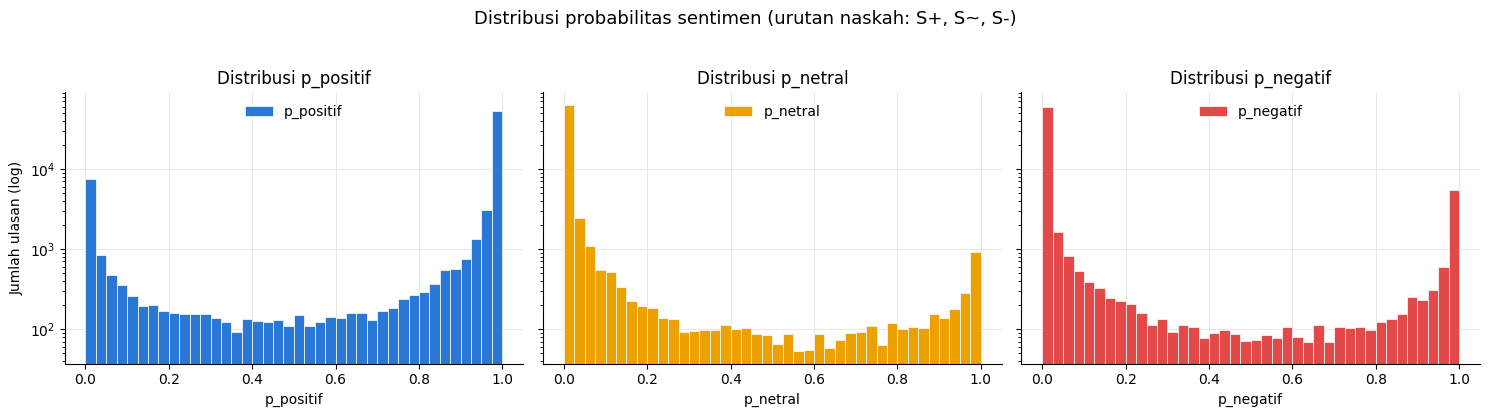

,p_positif,p_netral,p_negatif
count,73184.0000,73184.0000,73184.0000
mean,0.8328,0.0488,0.1184
std,0.3400,0.1748,0.2976
min,0.0005,0.0004,0.0004
25%,0.9606,0.0011,0.0011
50%,0.9946,0.0023,0.0019
75%,0.9975,0.0077,0.0085
max,0.9988,0.9982,0.9984


In [15]:
h = hasil[~kosong].copy()
h["prob_maks"] = eda.prob_maks(h)
h["entropi"] = eda.entropi(h)
h["kata"] = eda.jumlah_kata(h[TEXT_COL])
h_inc = h[as_bool(h["include_for_inference"])]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, kol in zip(axes, URUTAN_NASKAH):
    nama = kol.removeprefix("p_")
    ax.hist(h[kol], bins=bins, color=WARNA[nama], edgecolor="white", linewidth=0.5, label=kol)
    ax.set_yscale("log"); ax.set_xlabel(f"{kol}"); ax.set_title(f"Distribusi {kol}")
    ax.legend(loc="upper center", frameon=False)
axes[0].set_ylabel("Jumlah ulasan (log)")
fig.suptitle("Distribusi probabilitas sentimen (urutan naskah: S+, S~, S-)", y=1.03, fontsize=13)
fig.tight_layout(); grafik.simpan(fig, "distribusi_probabilitas"); plt.show()
display(pilih_prob(h, URUTAN_NASKAH).describe().round(4))

**Interpretasi.** Ketiga probabilitas sangat terpolarisasi: sebagian besar ulasan memiliki p_positif mendekati 1 (median 0,995), sedangkan p_netral dan p_negatif umumnya mendekati 0 dengan ekor kecil di dekat 1.

### 6b. Proporsi label argmax

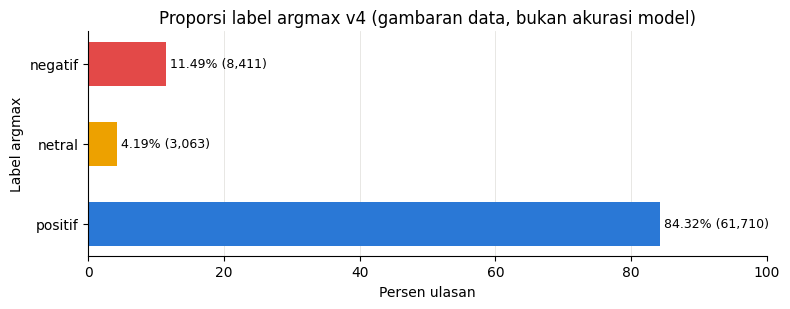

In [16]:
prop = h["label_argmax"].value_counts(normalize=True).reindex(list(LABEL_NAMES)[::-1]) * 100
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(prop.index, prop.values, color=[WARNA[k] for k in prop.index], height=0.55)
for y, (k, v) in enumerate(prop.items()):
    ax.text(v, y, f" {v:.2f}% ({int((h['label_argmax'] == k).sum()):,})", va="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("Persen ulasan"); ax.set_ylabel("Label argmax")
ax.set_title("Proporsi label argmax v4 (gambaran data, bukan akurasi model)")
ax.grid(axis="y", visible=False)
fig.tight_layout(); grafik.simpan(fig, "proporsi_argmax"); plt.show()

Catatan: label argmax hanya ringkasan keluaran model pada data ini; **bukan** ukuran akurasi. Akurasi domain marketplace belum diukur (perlu sampel berlabel manual, bukan rating bintang).

**Interpretasi.** Sebanyak 84,32% ulasan berlabel argmax positif, 11,49% negatif, dan 4,19% netral; proporsi ini hampir sama dengan v3 (83,98/12,06/3,96) dan hanya menggambarkan keluaran model pada data ini.

### 6c. Kepercayaan model

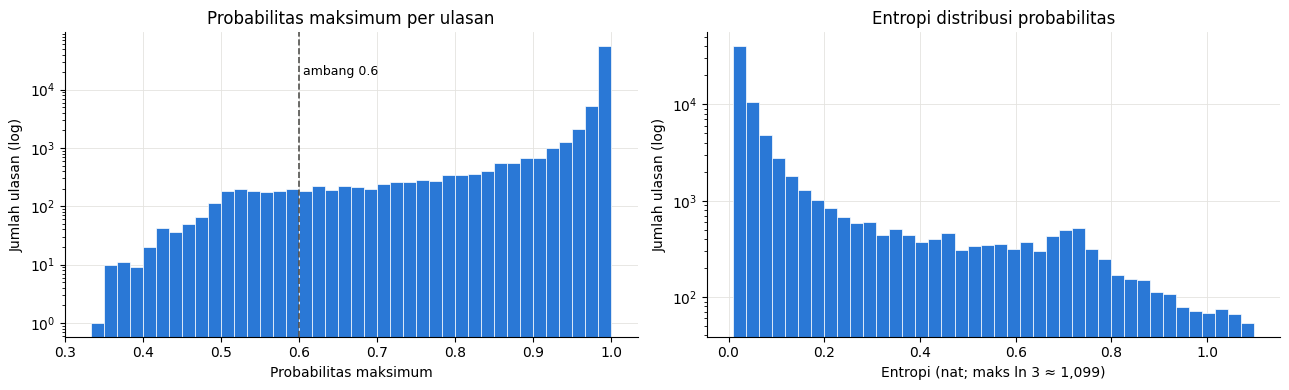

,kriteria,n,persen
0,prob_maks < 0.5,360,0.49
1,prob_maks < 0.6,1486,2.03
2,prob_maks < 0.8,4363,5.96


,n tidak yakin per label
label_argmax,
positif,647
negatif,460
netral,379


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(h["prob_maks"], bins=np.linspace(1/3, 1, 41), color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[0].axvline(AMBANG_TIDAK_YAKIN, color="#52514e", linestyle="--", linewidth=1.2)
axes[0].text(AMBANG_TIDAK_YAKIN, axes[0].get_ylim()[1] * 0.3, f" ambang {AMBANG_TIDAK_YAKIN}", fontsize=9)
axes[0].set_yscale("log"); axes[0].set_xlabel("Probabilitas maksimum"); axes[0].set_ylabel("Jumlah ulasan (log)")
axes[0].set_title("Probabilitas maksimum per ulasan")
axes[1].hist(h["entropi"], bins=40, color="#2a78d6", edgecolor="white", linewidth=0.5)
axes[1].set_yscale("log"); axes[1].set_xlabel("Entropi (nat; maks ln 3 ≈ 1,099)"); axes[1].set_ylabel("Jumlah ulasan (log)")
axes[1].set_title("Entropi distribusi probabilitas")
fig.tight_layout(); grafik.simpan(fig, "kepercayaan_model"); plt.show()

tidak_yakin = pd.DataFrame([(f"prob_maks < {a}", int((h["prob_maks"] < a).sum()),
                             eda.persen(int((h["prob_maks"] < a).sum()), len(h))) for a in (0.5, AMBANG_TIDAK_YAKIN, 0.8)],
                           columns=["kriteria", "n", "persen"])
display(tidak_yakin)
display(h[h["prob_maks"] < AMBANG_TIDAK_YAKIN]["label_argmax"].value_counts().rename("n tidak yakin per label").to_frame())

**Interpretasi.** Model sangat yakin pada sebagian besar ulasan: hanya 2,03% (1.486) ulasan memiliki probabilitas maksimum < 0,6, dan kelompok tidak yakin ini relatif lebih banyak berlabel netral dan negatif dibanding proporsi keseluruhannya.

### 6d. Hubungan dengan panjang teks

,n,p_negatif,p_netral,p_positif
kata,,,,
1-2,8503,0.0530,0.0146,0.9324
3-5,11450,0.0936,0.0642,0.8422
6-10,17040,0.1081,0.0781,0.8138
11-20,21790,0.1246,0.0511,0.8243
21-50,13130,0.1675,0.0197,0.8128
>50,1271,0.3038,0.0054,0.6908


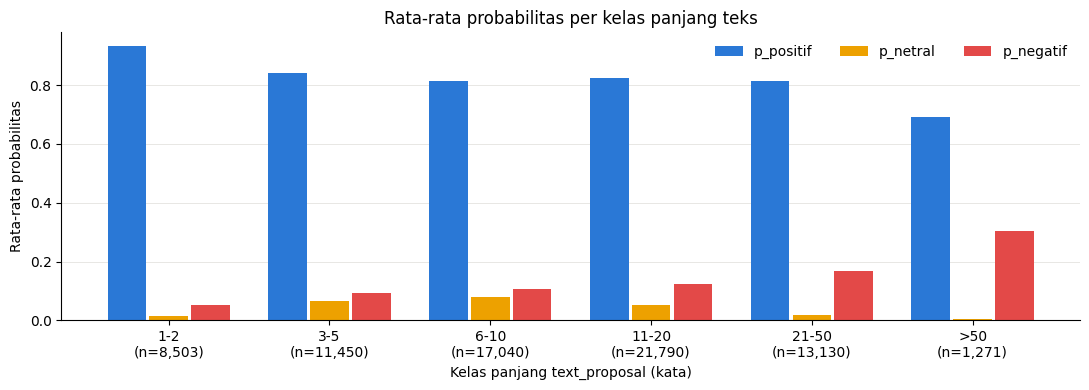

In [18]:
kelas = eda.kelas_panjang(h["kata"])
per_kelas = eda.rata2_per_kelas(h, kelas)
display(per_kelas.round(4))
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(per_kelas)); w = 0.26
for i, kol in enumerate(URUTAN_NASKAH):
    ax.bar(x + (i - 1) * w, per_kelas[kol], width=w - 0.02, color=WARNA[kol.removeprefix("p_")], label=kol)
ax.set_xticks(x, [f"{k}\n(n={n:,})" for k, n in zip(per_kelas.index.astype(str), per_kelas["n"])])
ax.set_xlabel("Kelas panjang text_proposal (kata)"); ax.set_ylabel("Rata-rata probabilitas")
ax.set_title("Rata-rata probabilitas per kelas panjang teks"); ax.legend(frameon=False, ncol=3)
ax.grid(axis="x", visible=False)
fig.tight_layout(); grafik.simpan(fig, "probabilitas_per_panjang"); plt.show()

**Interpretasi.** Rata-rata p_negatif naik seiring panjang ulasan (0,05 pada 1-2 kata menjadi 0,30 pada > 50 kata), sedangkan p_netral memuncak pada ulasan 6-10 kata; ulasan panjang cenderung berisi keluhan.

### 6e. Per toko dan per produk (produk dengan >= 3 ulasan include)

Produk >= 3 ulasan: 432 | Toko >= 3 ulasan: 151


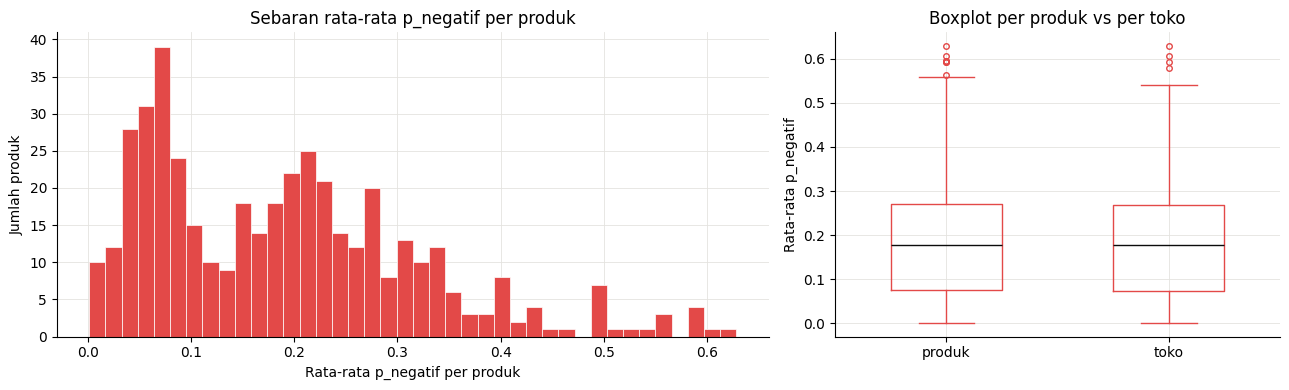

10 produk dengan rata-rata p_negatif TERTINGGI


,nama_toko,nama_produk,n,p_positif,p_netral,p_negatif
0,Mutiara.Ponsel,Samsung J2 Prime,22,0.3132,0.0582,0.6286
1,GALAXI.29,Samsung Galaxy A01,14,0.3779,0.0156,0.6065
2,Magic Space,Huawei Pura P90,46,0.3840,0.0202,0.5957
3,LANGGANAN SPART PART,J2 Prime,645,0.3563,0.0499,0.5938
4,Magic Space,Huawei Pura 80,37,0.3867,0.0208,0.5925
5,Magic Space,Nokia G42 5G,37,0.3867,0.0208,0.5925
6,Omni888,Oppo A31,11,0.3728,0.0631,0.5641
7,LANGGANAN SPART PART,Samsung J2 Prime,442,0.3987,0.0421,0.5592
8,Mitra_Cellular,infinix smart 9,24,0.4337,0.0130,0.5533
9,Galaxi,Samsung A01,12,0.4406,0.0181,0.5413


10 produk dengan rata-rata p_negatif TERENDAH


,nama_toko,nama_produk,n,p_positif,p_netral,p_negatif
0,TEMU.TOKO,Samsung Galaxy A15,3,0.9944,0.0044,0.0012
1,TEMU.TOKO,Samsung S25 Ultra,3,0.9944,0.0044,0.0012
2,TIGER BROTHER CELL Official Store,Vivo Y05,8,0.9950,0.0033,0.0017
3,Permatacahh,Samsung Galaxy A05s A04s RAM 6:128 A04 : A04e,9,0.8856,0.1114,0.0030
4,king77.toko,oppo a71,12,0.9869,0.0099,0.0032
5,OPPO Indonesia Official Store,Oppo Reno16 Pro,18,0.9857,0.0094,0.0049
6,realme,realme Note 80 4GB+8GB*|64GB,17,0.6297,0.3608,0.0096
7,vivo Official Store,Vivo T5 Pro 5G,52,0.9422,0.0446,0.0132
8,vivo Official Store,Vivo Y05,127,0.9650,0.0217,0.0133
9,Mixc Official Store,Realme Note 80,34,0.9549,0.0299,0.0152


In [19]:
per_produk = eda.rata2_per_produk(h_inc, min_ulasan=MIN_ULASAN)
per_toko = eda.rata2_per_produk(h_inc.assign(product_id=h_inc["nama_toko"]), min_ulasan=MIN_ULASAN)
print(f"Produk >= {MIN_ULASAN} ulasan: {len(per_produk)} | Toko >= {MIN_ULASAN} ulasan: {len(per_toko)}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].hist(per_produk["p_negatif"], bins=40, color=WARNA["negatif"], edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Rata-rata p_negatif per produk"); axes[0].set_ylabel("Jumlah produk")
axes[0].set_title("Sebaran rata-rata p_negatif per produk")
axes[1].boxplot([per_produk["p_negatif"], per_toko["p_negatif"]], tick_labels=["produk", "toko"], widths=0.5,
                medianprops={"color": "#0b0b0b"}, boxprops={"color": WARNA["negatif"]},
                whiskerprops={"color": WARNA["negatif"]}, capprops={"color": WARNA["negatif"]},
                flierprops={"markeredgecolor": WARNA["negatif"], "markersize": 4})
axes[1].set_ylabel("Rata-rata p_negatif"); axes[1].set_title("Boxplot per produk vs per toko")
fig.tight_layout(); grafik.simpan(fig, "p_negatif_per_produk"); plt.show()
kolom = ["nama_toko", "nama_produk", "n", "p_positif", "p_netral", "p_negatif"]
print("10 produk dengan rata-rata p_negatif TERTINGGI")
display(per_produk.sort_values(["p_negatif", "product_id"], ascending=[False, True]).head(10)[kolom].round(4).reset_index(drop=True))
print("10 produk dengan rata-rata p_negatif TERENDAH")
display(per_produk.sort_values(["p_negatif", "product_id"], ascending=[True, True]).head(10)[kolom].round(4).reset_index(drop=True))

**Interpretasi.** Rata-rata p_negatif per produk berkisar 0,00-0,63 dengan median sekitar 0,18; produk dengan p_negatif tertinggi didominasi seri lama (Samsung J2 Prime, Galaxy A01) dan beberapa pasangan berkas identik (Magic Space Huawei Pura 80 / Nokia G42) yang menunjukkan masalah duplikat lintas produk.

### 6f. Contoh evolusi waktu (gambaran masukan HMM)
Tiga produk dengan ulasan include terbanyak; ulasan diurutkan seperti ekspor sekuens (timestamp, lalu
`row_order`). Garis tipis = nilai per ulasan; garis tebal = rata-rata bergerak 25 ulasan.

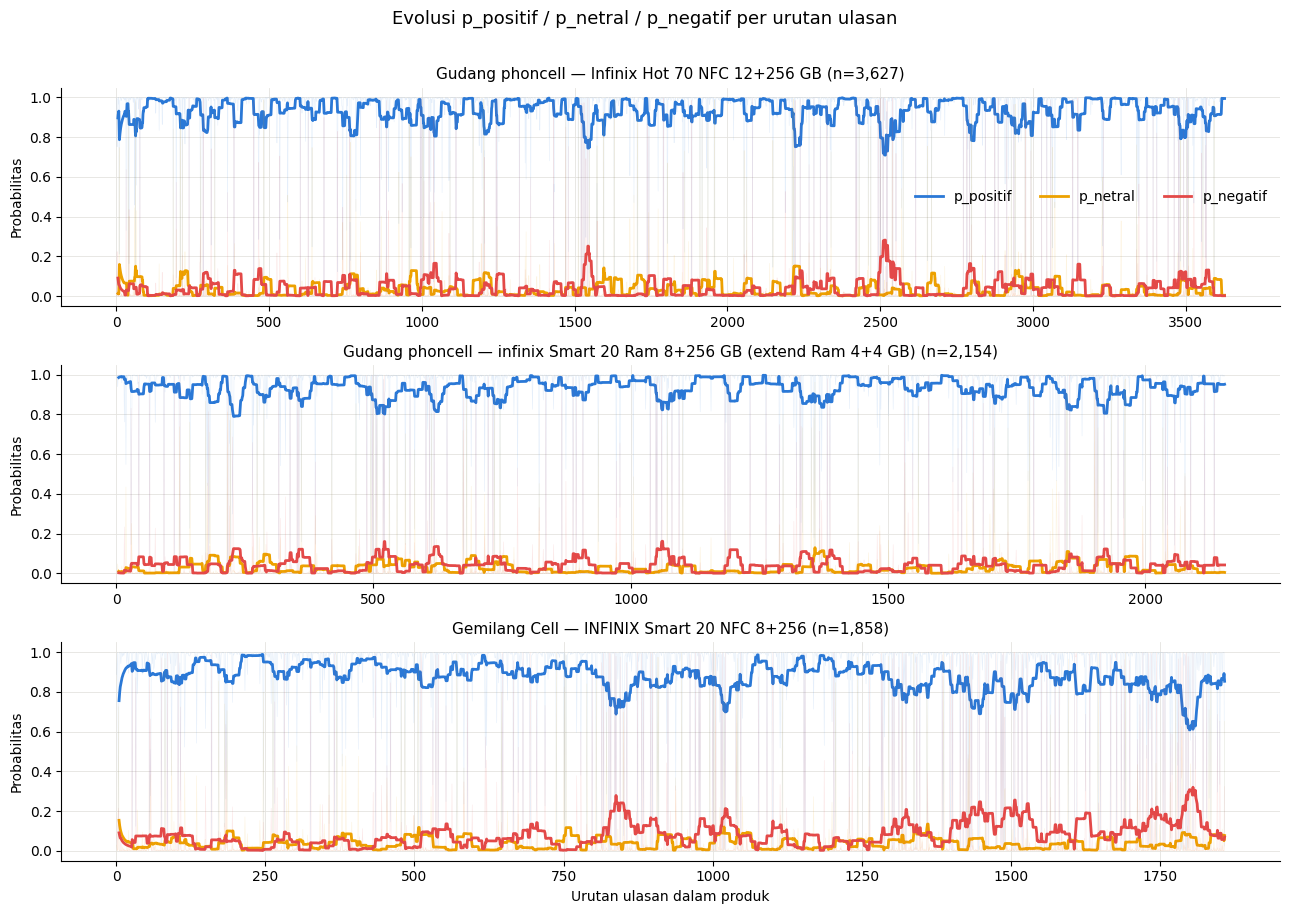

In [20]:
top3 = h_inc["product_id"].value_counts().head(3).index
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharey=True)
for ax, pid in zip(axes, top3):
    sub = h_inc[h_inc["product_id"] == pid].assign(_ts=lambda d: eda.parse_ts(d["timestamp"]))
    sub = sub.sort_values(["_ts", "row_order", "review_id"], kind="mergesort", na_position="last").reset_index(drop=True)
    for kol in URUTAN_NASKAH:
        warna = WARNA[kol.removeprefix("p_")]
        ax.plot(sub.index + 1, sub[kol], color=warna, linewidth=0.4, alpha=0.12)
        ax.plot(sub.index + 1, sub[kol].rolling(25, min_periods=5).mean(), color=warna, linewidth=2, label=kol)
    ax.set_title(f"{sub['nama_toko'].iat[0]} — {sub['nama_produk'].iat[0]} (n={len(sub):,})", fontsize=11)
    ax.set_ylabel("Probabilitas")
axes[-1].set_xlabel("Urutan ulasan dalam produk")
axes[0].legend(frameon=False, ncol=3, loc="center right")
fig.suptitle("Evolusi p_positif / p_netral / p_negatif per urutan ulasan", y=1.01, fontsize=13)
fig.tight_layout(); grafik.simpan(fig, "evolusi_top3_produk"); plt.show()

**Interpretasi.** Pada tiga produk terbesar, rata-rata bergerak p_positif tetap tinggi (sekitar 0,8-1,0) dengan lonjakan p_negatif sesekali hingga sekitar 0,3, yaitu pola episodik yang hendak ditangkap HMM.

### 6g. Contoh teks (hanya text_proposal)

Teks identik hanya ditampilkan sekali (banyak ulasan berulang, lihat is_text_duplicate).

In [21]:
h_unik = h.drop_duplicates(TEXT_COL)
for nama in LABEL_NAMES:
    kol = f"p_{nama}"
    print(f"5 ulasan dengan {kol} tertinggi")
    display(h_unik.sort_values([kol, "review_id"], ascending=[False, True]).head(5)[[TEXT_COL, *URUTAN_NASKAH]].round(4).reset_index(drop=True))
print("5 ulasan paling tidak pasti (entropi tertinggi)")
display(h_unik.sort_values(["entropi", "review_id"], ascending=[False, True]).head(5)[[TEXT_COL, *URUTAN_NASKAH, "entropi"]].round(4).reset_index(drop=True))

5 ulasan dengan p_negatif tertinggi


,text_proposal,p_positif,p_netral,p_negatif
0,"PARAH NIH HP,HP PALSU DI JUAL,DASAR PENIPU LU",0.0009,0.0006,0.9984
1,hp gk bisa di pakai wa selalu spam ini tipu tipu namanya,0.0010,0.0006,0.9984
2,"HP kw HP palsu redmi 14c cuma mesin nya palsu jangan beli disini, gw jadi korban penip...",0.0009,0.0007,0.9984
3,yg di kirim memang benar hp Vivo tp enggak bisa buat komunikasi baru di pakai 5 hari s...,0.0010,0.0006,0.9984
4,parah benar hpnya bos kapok beli di lajada kamera belakang rusak merembet tauchrin eng...,0.0009,0.0007,0.9984


5 ulasan dengan p_netral tertinggi


,text_proposal,p_positif,p_netral,p_negatif
0,"Sensor sidik jari di sisi, Pengisian daya cepat 15W melalui USB-C,",0.0010,0.9982,0.0008
1,"Sensor sidik jari di sisi,",0.0009,0.9981,0.0010
2,"Pengisian daya cepat 15W melalui USB-C, Sensor sidik jari di sisi,",0.0012,0.9981,0.0008
3,"Dukungan headset berkabel stabil, Sensor sidik jari di sisi,",0.0013,0.9980,0.0007
4,Menunggu konfirmasi pengembalian barang dari seller,0.0007,0.9979,0.0015


5 ulasan dengan p_positif tertinggi


,text_proposal,p_positif,p_netral,p_negatif
0,kamera jernih dan nyaman digunakan sehari-hari saya suka model nya elegan warna biru n...,0.9988,0.0005,0.0006
1,Desain elegan compact bikin feel genggam nyaman sekali sangat cantik ada efek langit p...,0.9988,0.0006,0.0006
2,enak buat main game maupun foto foto desain nya sangat elegan Pokoknya hp ini cocok ba...,0.9988,0.0006,0.0006
3,Suka banget. Kameranya mantap. Dapat diskon lumayan banyak baik sepadan,0.9988,0.0006,0.0006
4,layarnya sangat jernih.mantap kamera bagus,0.9988,0.0006,0.0006


5 ulasan paling tidak pasti (entropi tertinggi)


,text_proposal,p_positif,p_netral,p_negatif,entropi
0,ponsel berfungsi baik. Seperti baru karena layar n backdoor sudah diganti baru.,0.3495,0.3283,0.3223,1.0980
1,jdjjdjdjdjkskskdjejejejdjjejejejejejejejejejejejejej,0.3197,0.3276,0.3526,1.0977
2,"Worth it mulus, baterai health 98 Nanti aq uodate bintang, coba pakai dulu",0.3291,0.3186,0.3524,1.0977
3,walaupun saya pesan yg ram 8 tapi yang di kirim ram 3 tapi enggak papa lah,0.3080,0.3405,0.3515,1.0971
4,"semua fungsi normal fitur aman Mendarat dengan mulus, fungsi semua normal",0.3591,0.3148,0.3261,1.0970


Contoh teks tertinggi per kelas cenderung berupa ulasan pendek dan tegas; ulasan paling tidak pasti biasanya bercampur pujian dan keluhan. Contoh ini ilustrasi, bukan evaluasi.

### 6h. Perbandingan dengan v3 pada review_id yang sama

review_id sama: 64,699 (berlabel di keduanya: 64,641)
Label argmax berubah: 0 (0.0%)
Selisih probabilitas maksimum |v4 - v3|: 4.15e-07
MAX_LENGTH v3 = 128 | v4 = 128  -> SAMA


v4,negatif,netral,positif
v3,,,
negatif,7796,0,0
netral,0,2557,0
positif,0,0,54288


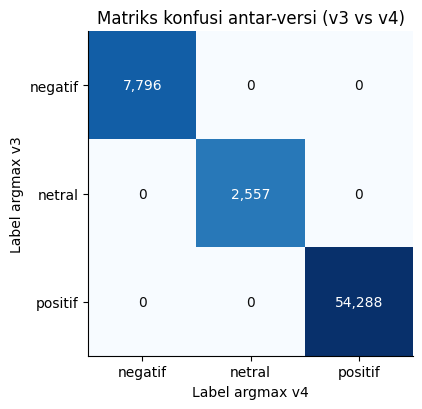

In [22]:
v3_meta = json.loads(V3_RINGKASAN.read_text(encoding="utf-8"))["meta"]
v3 = pd.read_csv(V3_CSV, encoding="utf-8-sig", usecols=["review_id", "label_argmax", *PROB_COLUMNS], low_memory=False)
gab = hasil[["review_id", "label_argmax", *PROB_COLUMNS]].merge(v3, on="review_id", suffixes=("_v4", "_v3"))
both = gab["label_argmax_v3"].notna() & gab["label_argmax_v4"].notna()
berubah_label = int((gab.loc[both, "label_argmax_v3"] != gab.loc[both, "label_argmax_v4"]).sum())
selisih = max(float((gab[f"{k}_v4"] - gab[f"{k}_v3"]).abs().max()) for k in PROB_COLUMNS)
print(f"review_id sama: {len(gab):,} (berlabel di keduanya: {int(both.sum()):,})")
print(f"Label argmax berubah: {berubah_label:,} ({eda.persen(berubah_label, int(both.sum()), 3)}%)")
print(f"Selisih probabilitas maksimum |v4 - v3|: {selisih:.2e}")
print(f"MAX_LENGTH v3 = {v3_meta['max_length']} | v4 = {MAX_LENGTH}"
      + ("  -> SAMA" if v3_meta["max_length"] == MAX_LENGTH else "  -> BERBEDA: perubahan label sebagian karena pemotongan"))
konfusi = eda.matriks_konfusi(gab["label_argmax_v3"], gab["label_argmax_v4"])
konfusi.index.name, konfusi.columns.name = "v3", "v4"
display(konfusi)
fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(np.log10(konfusi.to_numpy() + 1), cmap="Blues")
for i in range(3):
    for j in range(3):
        v = konfusi.iat[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=10,
                color="white" if np.log10(v + 1) > np.log10(konfusi.to_numpy().max() + 1) * 0.6 else "#0b0b0b")
ax.set_xticks(range(3), LABEL_NAMES); ax.set_yticks(range(3), LABEL_NAMES)
ax.set_xlabel("Label argmax v4"); ax.set_ylabel("Label argmax v3")
ax.set_title("Matriks konfusi antar-versi (v3 vs v4)"); ax.grid(False)
fig.tight_layout(); grafik.simpan(fig, "konfusi_v3_v4"); plt.show()

**Interpretasi.** Pada 64.699 review_id yang sama, tidak ada label argmax yang berubah dan selisih probabilitas maksimum di bawah 1e-6 (MAX_LENGTH v3 = v4 = 128), jadi perbedaan v4 dengan v3 sepenuhnya berasal dari data baru, bukan dari perubahan inferensi.

## 7. Sekuens
`src.export_sekuens` hanya menerima CSV hasil inferensi (`--input`); CSV itu sudah memuat seluruh kolom
parquet v4 (diverifikasi di bagian 5), jadi parquet v4 tercakup melalui CSV tersebut.

In [23]:
print(es.build_parser().format_help())
argv_sekuens = ["--input", str(HASIL_CSV), "--out-sekuens", str(SEKUENS_CSV), "--out-audit", str(AUDIT_CSV),
                "--min-ulasan", str(MIN_ULASAN)]
kode = es.main(argv_sekuens)
assert kode == es.EXIT_OK, f"Ekspor sekuens berhenti dengan kode {kode}"

usage: ipykernel_launcher.py [-h] [--input INPUT] [--out-sekuens OUT_SEKUENS]
                             [--out-audit OUT_AUDIT] [--min-ulasan MIN_ULASAN]

Ekspor sekuens sentimen per produk + jejak audit

options:
  -h, --help            show this help message and exit
  --input INPUT
  --out-sekuens OUT_SEKUENS
  --out-audit OUT_AUDIT
  --min-ulasan MIN_ULASAN



[LOLOS] baris_B_sama_input: B=73248, input=73248
[LOLOS] review_id_unik_B: unik=73248 dari 73248
[LOLOS] B_kolom_input_identik: 38 kolom input (product_id lama -> product_id_lama) + product_id baru + ['masuk_sekuens', 'alasan_keluar', 'seq_sekuens']; nilai dan urutan baris dibandingkan sel per sel
[LOLOS] product_id_baru_terisi: kosong=0; product_id == nama_toko + '_' + nama_produk di semua baris
[LOLOS] pemetaan_1_ke_1: product_id lama=432, baru=432, pasangan unik=432
[LOLOS] seq_sama_dengan_pengelompokan_lama: seq_sekuens dan alasan_keluar dibandingkan pada 73248 baris (review_id sama, urutan input)
[LOLOS] kolom_A_persis: ['product_id', 'nama_toko', 'nama_produk', 'timestamp', 'seq', 'p_positif', 'p_netral', 'p_negatif']
[LOLOS] kunci_product_id_seq_unik: duplikat (product_id, seq) di A=0, di B masuk=0
[LOLOS] A_sama_B_masuk: A=71317, B masuk=71317; dicocokkan lewat (product_id, seq) vs (product_id, seq_sekuens); probabilitas (teks), nama, dan timestamp identik
[LOLOS] seq_berurutan


Berkas ditulis:
  "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/sentiment/sekuens_produk_v4.csv"
  "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/audit_v4/sekuens_audit_v4.csv"
  "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/audit_v4/ekspor_sekuens_dikeluarkan.csv"
  "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/audit_v4/ekspor_sekuens_laporan.md"
  "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/audit_v4/ekspor_sekuens_ringkasan.json"
  "/Users/asyzyni/Desktop/TA/Kode dan Eksperimen/Kode TA/outputs/audit_v4/CHECKSUMS.txt"


In [24]:
ring_sek = json.loads((AUDIT_CSV.parent / es.NAMA_RINGKASAN).read_text(encoding="utf-8"))
sekuens = pd.read_csv(SEKUENS_CSV, encoding="utf-8-sig")
print(f"Baris sekuens: {ring_sek['n_baris_sekuens']:,} | Produk sekuens: {ring_sek['n_produk_sekuens']} "
      f"| Baris dikeluarkan: {ring_sek['n_baris_dikeluarkan']:,} | Produk hilang: {ring_sek['n_produk_hilang']}")
print("Produk tanpa sekuens:", ring_sek["produk_hilang"])
display(pd.Series(ring_sek["panjang_sekuens_T"], name="panjang sekuens T").to_frame())
alasan = pd.Series(ring_sek["baris_per_alasan_keluar"], name="n").to_frame()
alasan["persen_dari_input"] = (100 * alasan["n"] / ring_sek["n_baris_input"]).round(2)
display(alasan)
assert list(sekuens.columns) == es.SEKUENS_COLUMNS

contoh_pid = sekuens["product_id"].value_counts().pipe(lambda s: s[s >= 10]).sort_index().index[0]
print(f"Contoh Tabel 3.2 untuk produk: {contoh_pid}")
display(sekuens[sekuens["product_id"] == contoh_pid].head(10).reset_index(drop=True))

Baris sekuens: 71,317 | Produk sekuens: 431 | Baris dikeluarkan: 1,931 | Produk hilang: 1
Produk tanpa sekuens: ['Abassystore.id_VIVO Y20 RAM 8+256GB']


,panjang sekuens T
min,3.0
median,61.0
p95,508.5
maks,3625.0


,n,persen_dari_input
teks_kosong,64,0.09
bukan_include_for_inference,354,0.48
timestamp_tidak_valid,1513,2.07
produk_kurang_dari_3_ulasan,0,0.00


Contoh Tabel 3.2 untuk produk: 1688.shopp_Oppo A31


,product_id,nama_toko,nama_produk,timestamp,seq,p_positif,p_netral,p_negatif
0,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-04-02 01:42:00,1,0.994114,0.004025,0.001861
1,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-04-02 08:02:00,2,0.969245,0.018829,0.011925
2,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-04-03 20:05:00,3,0.080062,0.842433,0.077505
3,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-04-04 12:20:00,4,0.992224,0.004491,0.003285
4,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-04-05 10:10:00,5,0.998029,0.001009,0.000962
5,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-06-11 17:51:00,6,0.997490,0.001256,0.001253
6,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-06-14 12:48:00,7,0.948972,0.043087,0.007942
7,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-06-17 11:13:00,8,0.000670,0.997705,0.001625
8,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-06-19 02:47:00,9,0.998451,0.000731,0.000817
9,1688.shopp_Oppo A31,1688.shopp,Oppo A31,2026-06-29 13:25:00,10,0.997872,0.001250,0.000877


**Interpretasi.** Sebanyak 71.317 ulasan dari 431 produk masuk sekuens; 1.931 baris dikeluarkan, terutama karena timestamp relatif/tidak valid (1.513), dan satu produk hilang karena tidak memiliki ulasan bertimestamp valid.

## 8. Ringkasan akhir

In [25]:
dist = r["distribusi_argmax"]
ringkasan_angka = {
    "versi": "v4", "dibuat": datetime.now().astimezone().isoformat(timespec="seconds"),
    "provenance": provenance, "run_mode": RUN_MODE,
    "n_berkas_csv_data": n_berkas_csv,
    "n_berkas_dikecualikan_aturan_salinan": int((pengecualian["keputusan"] == "kecualikan").sum()),
    "n_berkas_diproses": int((manifest["status"] == "diproses").sum()),
    "n_berkas_tanpa_kolom_ulasan": int(manifest["status"].str.startswith("dilewati").sum()),
    "n_toko": int(df["nama_toko"].nunique()), "n_produk": int(df["product_id"].nunique()),
    "n_ulasan_bersih": int(len(df)),
    "n_include_for_inference": int(as_bool(df["include_for_inference"]).sum()),
    "n_teks_tidak_kosong": int((~as_bool(df["text_proposal_kosong"])).sum()),
    "n_diinferensi": r["n_diinferensi"], "n_kosong": r["n_kosong"],
    "distribusi_argmax": dist, "rata2_probabilitas": r["rata2_probabilitas"],
    "max_length": MAX_LENGTH, "n_terpotong": r["n_terpotong"], "persen_terpotong": r["persen_terpotong"],
    "persen_terpotong_per_max_length": terpotong.set_index("max_length")["persen_terpotong"].to_dict(),
    "n_tidak_yakin_prob_maks_lt_0_6": int((h["prob_maks"] < AMBANG_TIDAK_YAKIN).sum()),
    "durasi_inferensi_detik": round(durasi_penuh, 1),
    "sekuens": {k: ring_sek[k] for k in ["n_baris_sekuens", "n_produk_sekuens", "n_baris_dikeluarkan",
                                          "n_produk_hilang", "baris_per_alasan_keluar", "panjang_sekuens_T"]},
    "perbandingan_v3": {"n_review_id_sama": int(len(gab)), "n_label_berubah": berubah_label,
                        "persen_label_berubah": eda.persen(berubah_label, int(both.sum()), 3),
                        "max_length_v3": v3_meta["max_length"]},
    "keluaran": {k: str(Path(v).relative_to(OUT_ROOT)) for k, v in
                 {"sentimen": HASIL_CSV, "sekuens": SEKUENS_CSV, "audit": AUDIT_CSV, "grafik": FIG_DIR}.items()},
    "grafik": [p.name for p in grafik.berkas],
}
RINGKASAN_JSON.parent.mkdir(parents=True, exist_ok=True)
with open(RINGKASAN_JSON, "x", encoding="utf-8") as f:
    json.dump(ringkasan_angka, f, ensure_ascii=False, indent=2, default=str)

tampil = {
    "berkas CSV data": n_berkas_csv, "berkas diproses": ringkasan_angka["n_berkas_diproses"],
    "berkas dikecualikan (salinan)": ringkasan_angka["n_berkas_dikecualikan_aturan_salinan"],
    "produk": ringkasan_angka["n_produk"], "ulasan bersih": len(df),
    "include_for_inference": ringkasan_angka["n_include_for_inference"],
    "baris diinferensi": r["n_diinferensi"],
    **{f"argmax {k} (%)": dist[k]["persen"] for k in LABEL_NAMES},
    f"% terpotong (max_length={MAX_LENGTH})": r["persen_terpotong"],
    "produk di sekuens": ring_sek["n_produk_sekuens"], "baris sekuens": ring_sek["n_baris_sekuens"],
}
display(pd.Series({k: (f"{v:,}" if isinstance(v, int) else v) for k, v in tampil.items()}, name="v4", dtype=object).to_frame())
print(f'Disimpan: "{RINGKASAN_JSON.relative_to(OUT_ROOT)}"')
print("Grafik:", ", ".join(p.name for p in grafik.berkas))

,v4
berkas CSV data,456
berkas diproses,438
berkas dikecualikan (salinan),14
produk,432
ulasan bersih,"73,248"
include_for_inference,"72,881"
baris diinferensi,"73,184"
argmax negatif (%),11.49
argmax netral (%),4.19
argmax positif (%),84.32


Disimpan: "reports/v4/ringkasan_angka_v4.json"
Grafik: 01_corong_data.png, 02_ulasan_per_produk.png, 03_panjang_teks.png, 04_ulasan_per_bulan.png, 05_top_slang.png, 06_kata_bigram.png, 07_distribusi_probabilitas.png, 08_proporsi_argmax.png, 09_kepercayaan_model.png, 10_probabilitas_per_panjang.png, 11_p_negatif_per_produk.png, 12_evolusi_top3_produk.png, 13_konfusi_v3_v4.png
